# BIG Kalimantan peatland layer: initial EDA

This notebook summarizes the 146 polygons in the downloaded BIG GeoJSON. Area is calculated geodesically on WGS84 in hectares. These are **sums of feature areas**, not yet a dissolved peatland mask; overlapping features would be counted more than once.


In [11]:
import json
from pathlib import Path

import pandas as pd
from pyproj import Geod
from shapely.geometry import shape


## Load features and flatten the attributes

`pd.read_json` leaves each whole GeoJSON feature nested in a `features` column. The code below makes one row per polygon with `landform` and `bhnindk` available as ordinary columns.


In [12]:
source = Path("data/raw/peatland/big_peta_lahan_gambut_kalimantan.geojson")
with source.open(encoding="utf-8") as file:
    geojson = json.load(file)

features = geojson["features"]
df = pd.DataFrame([feature["properties"] for feature in features])
df["geometry"] = [shape(feature["geometry"]) for feature in features]

print(f"Features: {len(df)}")
print(f"Valid geometries: {df.geometry.map(lambda geom: geom.is_valid).sum()} / {len(df)}")
df[["objectid", "landform", "bhnindk", "usda1"]].head()


Features: 146
Valid geometries: 146 / 146


,objectid,landform,bhnindk,usda1
0,1,Rawa Belakang Sungai Meander (Backswamp),Endapan organik,Terric Haplosaprists
1,2,Rawa Belakang Sungai Meander (Backswamp),Endapan organik,Terric Haplosaprists
2,3,Rawa Belakang Sungai Meander (Backswamp),Endapan organik dan mineral,Terric Haplosaprists
3,4,Rawa Belakang Sungai Meander (Backswamp),Endapan organik dan mineral,Terric Haplosaprists
4,5,Rawa Belakang Sungai Meander (Backswamp),Endapan organik,Terric Haplohemists


## Calculate polygon area

The coordinates are longitude and latitude, so `shapely.geometry.area` would return square degrees. `pyproj.Geod` computes area on the WGS84 ellipsoid in square metres; divide by 10,000 for hectares.


In [13]:
geod = Geod(ellps="WGS84")
df["area_ha"] = df.geometry.map(
    lambda geom: abs(geod.geometry_area_perimeter(geom)[0]) / 10_000
)
print(f"Sum of feature areas: {df.area_ha.sum():,.0f} ha")


Sum of feature areas: 4,528,191 ha


## Polygon counts and area by landform


In [14]:
by_landform = (
    df.groupby("landform", dropna=False)
      .agg(polygons=("area_ha", "size"), area_ha=("area_ha", "sum"))
      .sort_values("area_ha", ascending=False)
)
by_landform.round(1)


,polygons,area_ha
landform,,
Gambut Topogen Air Tawar (100 cm - < 200 cm),11,735755.4
Gambut Topogen Air Tawar (200 cm - < 300 cm),8,668546.9
Kubah Gambut (300 cm - < 500 cm),5,477714.5
Gambut Topogen Air Tawar (50 cm - < 100 cm),9,453348.9
Kubah Gambut (500 cm - < 700 cm),3,413151.0
Tepi Kubah Gambut (100 cm - < 200 cm),4,385559.5
Tepi Kubah Gambut (200 cm - < 300 cm),5,251723.5
Gambut Topogen Air Tawar (300 cm - < 500 cm),9,218869.3
Gambut Topogen Air Payau (100 cm - < 200 cm),10,178505.0


## Polygon counts and area by parent material (`bhnindk`)


In [15]:
by_material = (
    df.groupby("bhnindk", dropna=False)
      .agg(polygons=("area_ha", "size"), area_ha=("area_ha", "sum"))
      .sort_values("area_ha", ascending=False)
)
by_material.round(1)


,polygons,area_ha
bhnindk,,
Endapan organik,136,4468657.1
Endapan organik dan mineral,10,59533.8


## Combined breakdown

Use this table to see how parent material varies within each landform. It is descriptive only; we have not decided which classes make up the peatland boundary.


In [16]:
by_landform_material = (
    df.groupby(["landform", "bhnindk"], dropna=False)
      .agg(polygons=("area_ha", "size"), area_ha=("area_ha", "sum"))
      .sort_values("area_ha", ascending=False)
)
by_landform_material.round(1)


,,polygons,area_ha
landform,bhnindk,,
Gambut Topogen Air Tawar (100 cm - < 200 cm),Endapan organik,11,735755.4
Gambut Topogen Air Tawar (200 cm - < 300 cm),Endapan organik,8,668546.9
Kubah Gambut (300 cm - < 500 cm),Endapan organik,5,477714.5
Gambut Topogen Air Tawar (50 cm - < 100 cm),Endapan organik,9,453348.9
Kubah Gambut (500 cm - < 700 cm),Endapan organik,3,413151.0
Tepi Kubah Gambut (100 cm - < 200 cm),Endapan organik,4,385559.5
Tepi Kubah Gambut (200 cm - < 300 cm),Endapan organik,5,251723.5
Gambut Topogen Air Tawar (300 cm - < 500 cm),Endapan organik,9,218869.3
Gambut Topogen Air Payau (100 cm - < 200 cm),Endapan organik,10,178505.0


## Map the polygons within Kalimantan

The pale background and province borders come from BIG’s [Batas Administrasi Provinsi polygon layer](https://geoservices.big.go.id/gis/rest/services/STIG/Batas_Provinsi/MapServer/0). The downloaded five-province GeoJSON is at `data/raw/boundaries/big_kalimantan_provinces.geojson`. BIG returns four coordinate values per point here; the plotting code keeps longitude and latitude, then simplifies the boundary **for display only**. We are not using this display geometry to calculate area or define the study grid.

Blue polygons have “Gambut” in the landform name; orange polygons have other names. This visual grouping is **not** our final peatland classification.


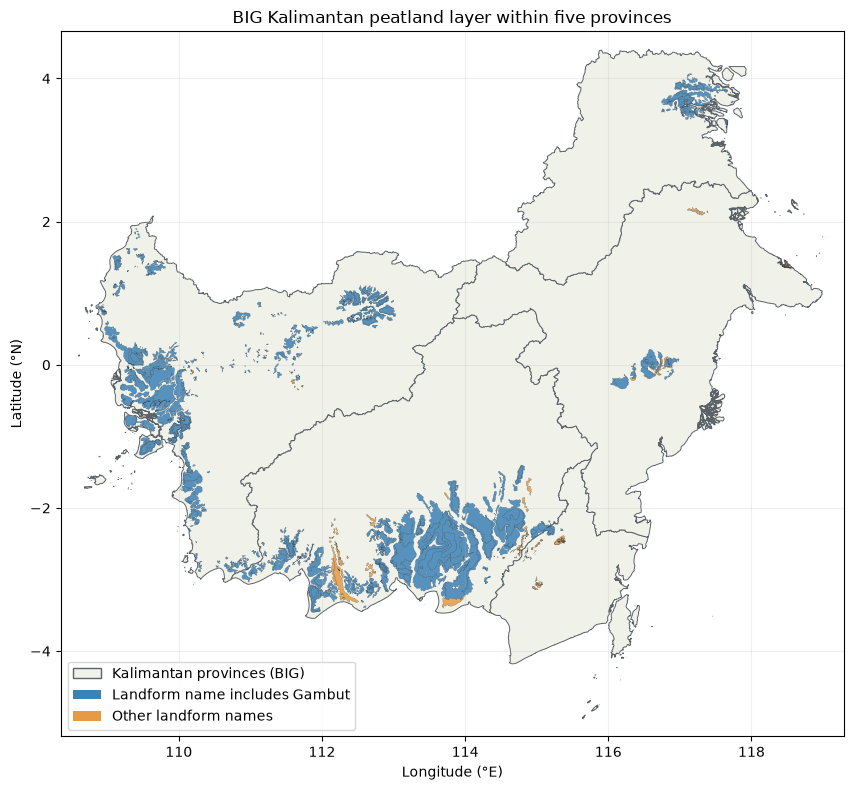

In [18]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from shapely.plotting import plot_polygon

with Path("data/raw/boundaries/big_kalimantan_provinces.geojson").open(encoding="utf-8") as file:
    province_geojson = json.load(file)

def keep_xy(coordinates):
    """Discard ArcGIS elevation/measure values, retaining longitude and latitude."""
    if isinstance(coordinates[0], (int, float)):
        return coordinates[:2]
    return [keep_xy(part) for part in coordinates]

provinces = []
for feature in province_geojson["features"]:
    raw_geometry = feature["geometry"]
    geometry_2d = shape({
        "type": raw_geometry["type"],
        "coordinates": keep_xy(raw_geometry["coordinates"]),
    })
    provinces.append((
        feature["properties"]["WADMPR"],
        geometry_2d.simplify(0.002, preserve_topology=True),
    ))

fig, ax = plt.subplots(figsize=(11, 8))

for name, geometry in provinces:
    plot_polygon(
        geometry, ax=ax, add_points=False,
        facecolor="#f0f1e9", edgecolor="#5b6268", linewidth=0.7,
    )

for row in df.itertuples():
    named_gambut = "gambut" in row.landform.lower()
    plot_polygon(
        row.geometry, ax=ax, add_points=False,
        facecolor="#3b82b6" if named_gambut else "#e69a45",
        edgecolor="#25313b", linewidth=0.15, alpha=0.85,
    )

all_geometries = [geometry for _, geometry in provinces] + df.geometry.tolist()
bounds = pd.DataFrame([geometry.bounds for geometry in all_geometries],
                      columns=["min_lon", "min_lat", "max_lon", "max_lat"])
ax.set_xlim(bounds.min_lon.min() - 0.25, bounds.max_lon.max() + 0.25)
ax.set_ylim(bounds.min_lat.min() - 0.25, bounds.max_lat.max() + 0.25)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("BIG Kalimantan peatland layer within five provinces")
ax.grid(alpha=0.2)
ax.legend(handles=[
    Patch(facecolor="#f0f1e9", edgecolor="#5b6268", label="Kalimantan provinces (BIG)"),
    Patch(facecolor="#3b82b6", label="Landform name includes Gambut"),
    Patch(facecolor="#e69a45", label="Other landform names"),
], loc="lower left")
plt.tight_layout()
plt.show()


The map looks similar to the one shown in the paper by mahdiyasa2026

